# Лабораторная работа №2: Экспертные системы

## 1. Подготовка окружения
Импортируем необходимые библиотеки для визуализации результатов и тестирования.

In [21]:
import matplotlib.pyplot as plt 
import ipytest
import pytest

#Настройка ipytest для тестов в Jupyter
ipytest.autoconfig()

## 2. База знаний
Класс `KnowledgeBase`, который инкапсулирует данные предметной области:
- `scenarios` - словарь возможных результатов с их характеристиками и весами.
- `questions` - словарь вопросов для пользователя, связанных с характеристиками.

In [ ]:
class KnowledgeBase:
    """Класс, представляющий расширенную базу знаний экспертной системы."""
    
    def __init__(self):
        # Игра - {признаки и их веса, описание}
        self.__scenarios = {
            # --- Экшены, Шутеры и Открытый мир ---
            "Серия Far Cry (напр. Far Cry 3)": {
                "features": {"открытый мир": 3, "шутер": 3, "стелс": 2, "выживание": 1, "сюжет": 2},
                "description": "Шутер от первого лица в открытом мире с захватом аванпостов и харизматичными злодеями."
            },
            "Cyberpunk 2077": {
                "features": {"открытый мир": 3, "фантастика": 3, "шутер": 2, "сюжет": 3, "рпг": 2},
                "description": "Масштабная RPG в сеттинге будущего от первого лица."
            },
            "Red Dead Redemption 2": {
                "features": {"открытый мир": 3, "сюжет": 3, "шутер": 2, "рпг": 1, "симулятор": 1},
                "description": "Глубокая и реалистичная история о Диком Западе от создателей GTA."
            },
            "Grand Theft Auto V (GTA 5)": {
                "features": {"открытый мир": 3, "шутер": 2, "сюжет": 2, "мультиплеер": 2, "спорт_гонки": 2},
                "description": "Легендарный экшен про криминальный мир с огромным городом и онлайном."
            },
            "Half-Life 2": {
                "features": {"шутер": 3, "сюжет": 3, "фантастика": 3},
                "description": "Культовый линейный научно-фантастический шутер с физическими головоломками."
            },
            "DOOM Eternal": {
                "features": {"шутер": 3, "фантастика": 2, "сложная": 2},
                "description": "Максимально динамичный и брутальный шутер про уничтожение демонов."
            },
            "HITMAN 3": {
                "features": {"стелс": 3, "открытый мир": 1, "шутер": 1},
                "description": "Симулятор наемного убийцы, где каждый уровень — это песочница с десятками способов устранения цели."
            },

            # --- RPG и Фэнтези ---
            "The Witcher 3: Wild Hunt": {
                "features": {"открытый мир": 3, "фэнтези": 3, "сюжет": 3, "рпг": 3},
                "description": "Эпическая ролевая игра про охотника на чудовищ Геральта из Ривии."
            },
            "Baldur's Gate 3": {
                "features": {"рпг": 3, "фэнтези": 3, "сюжет": 3, "кооп": 3, "стратегия": 2},
                "description": "Партийная ролевая игра нового поколения по правилам D&D."
            },
            "The Elder Scrolls V: Skyrim": {
                "features": {"открытый мир": 3, "фэнтези": 3, "рпг": 3},
                "description": "Классика жанра RPG с полной свободой действий в мире драконов и магии."
            },
            "Elden Ring": {
                "features": {"открытый мир": 3, "фэнтези": 3, "сложная": 3, "рпг": 3},
                "description": "Масштабная и суровая игра от создателей Dark Souls."
            },
            "Dark Souls III": {
                "features": {"фэнтези": 3, "сложная": 3, "рпг": 2},
                "description": "Мрачная экшен-RPG, известная своей бескомпромиссной сложностью."
            },
            "Sekiro: Shadows Die Twice": {
                "features": {"сложная": 3, "стелс": 2, "сюжет": 2},
                "description": "Хардкорный экшен про ниндзя с потрясающей боевой системой парирований."
            },

            # --- Мультиплеер и Киберспорт ---
            "CS:GO / Counter-Strike 2": {
                "features": {"мультиплеер": 3, "шутер": 3, "киберспорт": 3},
                "description": "Самый популярный командный тактический шутер."
            },
            "Dota 2": {
                "features": {"мультиплеер": 3, "киберспорт": 3, "фэнтези": 2, "стратегия": 2},
                "description": "Сложная и глубокая MOBA-игра, собирающая миллионы игроков."
            },
            "Apex Legends": {
                "features": {"мультиплеер": 3, "шутер": 3, "киберспорт": 2, "фантастика": 2},
                "description": "Динамичная королевская битва (Battle Royale) с уникальными персонажами."
            },

            # --- Выживание (Survival) и Кооператив ---
            "Rust": {
                "features": {"выживание": 3, "мультиплеер": 3, "открытый мир": 2, "шутер": 2},
                "description": "Жестокий симулятор выживания, где другие игроки — ваша главная угроза."
            },
            "Subnautica": {
                "features": {"выживание": 3, "открытый мир": 3, "фантастика": 2, "хоррор": 1},
                "description": "Одиночное выживание в потрясающе красивом и опасном инопланетном океане."
            },
            "Left 4 Dead 2": {
                "features": {"кооп": 3, "шутер": 3, "хоррор": 2},
                "description": "Классический кооперативный шутер про отстрел толп зомби."
            },
            "Terraria": {
                "features": {"выживание": 2, "инди": 3, "кооп": 3, "открытый мир": 2, "фэнтези": 1},
                "description": "Двухмерная песочница с огромным количеством боссов, крафта и исследований."
            },
            "Phasmophobia": {
                "features": {"хоррор": 3, "кооп": 3, "инди": 2},
                "description": "Кооперативный психологический хоррор про охотников за привидениями."
            },
            "Dead by Daylight": {
                "features": {"мультиплеер": 3, "хоррор": 3, "кооп": 2},
                "description": "Асимметричный онлайн-хоррор, где один игрок — маньяк, а четверо — жертвы."
            },

            # --- Инди, Рогалики и Уютные игры ---
            "Stardew Valley": {
                "features": {"симулятор": 3, "инди": 3, "расслабляющая": 3, "кооп": 2},
                "description": "Уютный симулятор жизни в деревне с фермерством и рыбалкой."
            },
            "Hades": {
                "features": {"рогалик": 3, "инди": 3, "сюжет": 2, "сложная": 2, "фэнтези": 2},
                "description": "Динамичный рогалик с отличным сюжетом на основе греческой мифологии."
            },
            "The Binding of Isaac: Rebirth": {
                "features": {"рогалик": 3, "инди": 3, "сложная": 2, "хоррор": 1},
                "description": "Культовый рогалик с бесконечной реиграбельностью и мрачным стилем."
            },
            "Hollow Knight": {
                "features": {"инди": 3, "сложная": 3, "фэнтези": 2, "открытый мир": 1},
                "description": "Атмосферная метроидвания с красивой рисовкой и сложными боссами."
            },
            "Portal 2": {
                "features": {"кооп": 3, "сюжет": 3, "фантастика": 2},
                "description": "Шедевральная пространственная головоломка с отличным юмором."
            },

            # --- Стратегии и Симуляторы ---
            "Civilization VI": {
                "features": {"стратегия": 3, "мультиплеер": 2, "расслабляющая": 1},
                "description": "Глобальная пошаговая стратегия про развитие человеческой цивилизации."
            },
            "Hearts of Iron IV": {
                "features": {"стратегия": 3, "симулятор": 2, "сложная": 2},
                "description": "Глубокая глобальная стратегия в сеттинге Второй мировой войны."
            },
            "Cities: Skylines": {
                "features": {"стратегия": 2, "симулятор": 3, "расслабляющая": 2},
                "description": "Лучший современный градостроительный симулятор."
            },
            "Euro Truck Simulator 2": {
                "features": {"симулятор": 3, "открытый мир": 2, "расслабляющая": 3},
                "description": "Медитативный симулятор дальнобойщика по дорогам Европы."
            },
            "Age of Empires II: Definitive Edition": {
                "features": {"стратегия": 3, "мультиплеер": 2, "киберспорт": 1},
                "description": "Классическая стратегия в реальном времени (RTS) в историческом сеттинге."
            },

            # --- Спорт, Гонки и Хорроры ---
            "Forza Horizon 5": {
                "features": {"спорт_гонки": 3, "открытый мир": 3, "мультиплеер": 2, "расслабляющая": 1},
                "description": "Аркадная гонка с невероятной графикой в открытом мире Мексики."
            },
            "EA Sports FC 24 (ранее FIFA)": {
                "features": {"спорт_гонки": 3, "мультиплеер": 3, "киберспорт": 1},
                "description": "Главный футбольный симулятор в мире."
            },
            "Resident Evil 4 Remake": {
                "features": {"хоррор": 3, "шутер": 2, "сюжет": 2, "выживание": 1},
                "description": "Образцовый ремейк культового экшен-хоррора."
            }
        }
        
        # Вопросы для пользователя (переработанные под новые признаки)
        self.__questions = {
            "открытый мир": "Вам важно наличие большого открытого мира для свободного исследования?",
            "шутер": "Предпочитаете игры с огнестрельным оружием и перестрелками (шутеры)?",
            "сюжет": "Является ли для вас приоритетом глубокий, проработанный сюжет и история?",
            "фэнтези": "Любите ли вы сеттинг фэнтези (магия, мечи, эльфы, драконы)?",
            "фантастика": "Интересует ли вас научная фантастика, космос или киберпанк?",
            "мультиплеер": "Хотите играть по сети против других реальных игроков (PvP)?",
            "кооп": "Хотите проходить игру совместно с друзьями (кооператив)?",
            "сложная": "Нравится ли вам высокий уровень сложности, бросающий вызов (хардкор)?",
            "хоррор": "Любите ли вы пугающую атмосферу, монстров и жанр хоррор?",
            "выживание": "Интересует ли вас механика выживания (поиск ресурсов, крафт, строительство)?",
            "инди": "Как вы относитесь к небольшим независимым играм (инди) с необычными механиками?",
            "стратегия": "Нравится ли вам управлять армиями, строить базы или развивать цивилизации?",
            "симулятор": "Хотите ли вы реалистичный симулятор (вождения, фермы, градостроительства)?",
            "спорт_гонки": "Интересуют ли вас спортивные симуляторы или гонки на автомобилях?",
            "рпг": "Нравится ли вам прокачивать персонажа, выбирать классы и отыгрывать роль (RPG)?",
            "стелс": "Любите ли вы скрытное прохождение, устранение врагов без шума и тревоги?",
            "рогалик": "Нравятся ли вам игры, где уровни генерируются случайно, а после смерти нужно начинать заново (рогалики)?",
            "расслабляющая": "Ищете ли вы спокойную, расслабляющую игру, чтобы отдохнуть после тяжелого дня?",
            "киберспорт": "Интересуют ли вас соревновательные игры, по которым проводятся киберспортивные турниры?"
        }

    @property
    def scenarios(self):
        """Публичный доступ к приватному словарю сценариев."""
        return self.__scenarios

    @property
    def questions(self):
        """Публичный доступ к приватному словарю вопросов."""
        return self.__questions

## 3. Логика и интерфейс
Класс `ExpertSystem`, который принимает объект базы знаний и выполняет:
1. Опрос пользователя.
2. Подсчет баллов на основе совпадения признаков.
3. Графический вывод результатов.

In [18]:
class ExpertSystem:
    """Класс машины выводов и взаимодействия с пользователем."""
    
    def __init__(self, kb: KnowledgeBase):
        self.kb = kb
        
    def calculate_scores(self, user_answers: dict) -> dict:
        # Подсчет баллов для каждого сценария.
        scores = {}
        for scenario_name, data in self.kb.scenarios.items():
            score = 0
            for feature, weight in data["features"].items():
                if user_answers.get(feature, False):
                    score += weight
            scores[scenario_name] = score
        return scores

    def plot_results(self, scores: dict):
        # Графическая визуализация набранных баллов.
        sorted_scores = sorted(scores.items(), key=lambda item: item[1], reverse=True)
        games = [item[0] for item in sorted_scores]
        points = [item[1] for item in sorted_scores]

        plt.figure(figsize=(10, 4))
        # Лучший результат выделяем зеленым, остальные синим
        colors = ['#2ecc71' if i == 0 and points[0] > 0 else '#3498db' for i in range(len(games))]
        
        bars = plt.barh(games[::-1], points[::-1], color=colors[::-1])
        
        plt.xlabel('Набранные баллы', fontsize=12)
        plt.title('Результаты подбора', fontsize=14, fontweight='bold')
        plt.grid(axis='x', linestyle='--', alpha=0.7)

        for bar in bars:
            width = bar.get_width()
            plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, f'{int(width)} б.', 
                     va='center', ha='left', fontsize=10, fontweight='bold')

        plt.tight_layout()
        plt.show()

    def start_consultation(self):
        # Запуск системы
        print("--- Экспертная система подбора видеоигр ---")
        print("Отвечайте 'y' (да) или 'n' (нет) на следующие вопросы:\n")
        
        user_answers = {}
        for feature_key, question_text in self.kb.questions.items():
            while True:
                answer = input(f"{question_text} (y/n): ").strip().lower()
                if answer in ['y', 'yes', 'д', 'да']:
                    user_answers[feature_key] = True
                    break
                elif answer in ['n', 'no', 'н', 'нет']:
                    user_answers[feature_key] = False
                    break
                else:
                    print("Ошибка ввода. Пожалуйста, введите 'y' или 'n'.")
        
        # Подсчет и вывод результатов
        scores = self.calculate_scores(user_answers)
        self.display_recommendation(scores)
        self.plot_results(scores)
        
    def display_recommendation(self, scores: dict):
        # Вывод результатов
        sorted_scores = sorted(scores.items(), key=lambda item: item[1], reverse=True)
        best_game, best_score = sorted_scores[0]
        
        print("\n" + "-"*45)
        if best_score > 0:
            print(f"Рекомендация: **{best_game}** (Баллов: {best_score})")
            print(f"Описание: {self.kb.scenarios[best_game]['description']}")
        else:
            print("По вашим ответам ничего не найдено.")
        print("-"*45)

## 4. Тестирование
Тесты для проверки корректности работы базы знаний. (.ipytest нужен для работы в jupyter)

In [19]:
%%ipytest -v

def test_knowledge_base():
    # Проверка инициализации базы данных.
    kb = KnowledgeBase()
    assert "The Witcher 3" in kb.scenarios
    assert len(kb.questions) > 5

def test_expert_system_scoring():
    # Проверка логики подсчета баллов.
    kb = KnowledgeBase()
    es = ExpertSystem(kb)
    
    # Имитация ответов пользователя, подходящие для CS:GO
    mock_answers = {
        "мультиплеер": True,
        "шутер": True,
        "ферма": False
    }
    
    scores = es.calculate_scores(mock_answers)
    
    # Проверка, что CS:GO получил больше всего баллов
    assert scores["CS:GO / Counter-Strike 2"] == 6 # (3 за мультиплеер + 3 за шутер)
    assert scores["Stardew Valley"] == 0

======================================= test session starts =======================================
platform win32 -- Python 3.10.21, pytest-9.1.1, pluggy-1.6.0
rootdir: c:\ML_Reapet\practice
plugins: anyio-4.15.1
collected 2 items

t_f346d8cec8414b0692090f8582c02273.py ..                                                     [100%]

======================================== 2 passed in 0.02s ========================================


## 5. Запуск программы 
Инициализация объектов и запуск программы

--- Экспертная система подбора видеоигр ---
Отвечайте 'y' (да) или 'n' (нет) на следующие вопросы:


---------------------------------------------
Рекомендация: **Cyberpunk 2077** (Баллов: 7)
Описание: Масштабная RPG в сеттинге будущего от первого лица.
---------------------------------------------


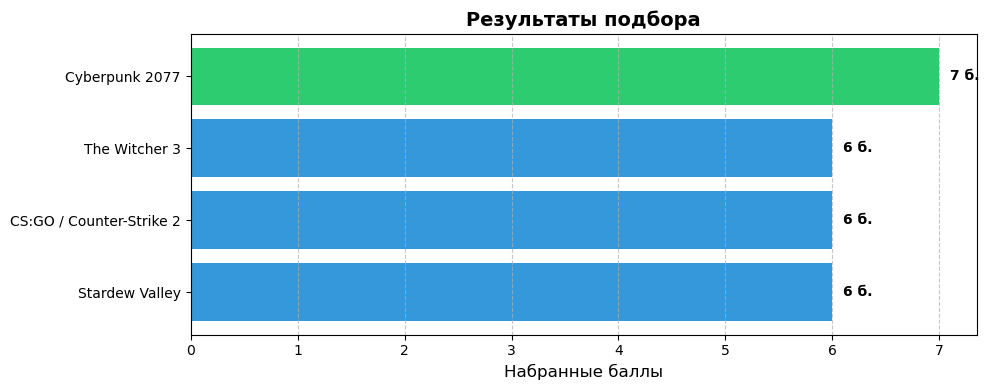

In [20]:
if __name__ == "__main__":
    # Инициализация базы знаний
    kb = KnowledgeBase()
    
    # Создание и запуск экспертной системы
    system = ExpertSystem(kb)
    
    # Раскомментить для запуска
    system.start_consultation()